# Manuscript Plots

Andrew E. Davidson  
aedaivds@ucsc.edu 11/10/2026

Copyright (c) 2026, Regents of the University of California All rights reserved. https://polyformproject.org/licenses/noncommercial/1.0.0

In [1]:
import matplotlib.pyplot as plt
import os
import pandas as pd

from pathlib import Path
import sys

# 11/3/26 Use the notebook path supplied by VS Code.
notebookPath = Path(__vsc_ipynb_file__)
notebookName = notebookPath.stem
notebookDir = str(notebookPath.parent)

import logging
#loglevel = "INFO"
loglevel = "WARN"
# logFMT = "%(asctime)s %(levelname)s [thr:%(threadName)s %(name)s %(funcName)s() line:%(lineno)s] [%(message)s]"
logFMT = "%(asctime)s %(levelname)s %(name)s %(funcName)s() line:%(lineno)s] [%(message)s]"
logging.basicConfig(format=logFMT, level=loglevel)    
logger = logging.getLogger(notebookName)



In [2]:
# set up PYTHONPATH
ORIG_PYTHONPATH = os.environ['PYTHONPATH']

intraExtraRNA_POCModules=notebookPath.parent.joinpath("../python/src")
print("intraExtraRNA_POCModules: {}\n".format(intraExtraRNA_POCModules))

# to be able to import our local python files we need to set the sys.path
# https://stackoverflow.com/a/50155834
sys.path.append( str(intraExtraRNA_POCModules) )


intraExtraRNA_POCModules: /private/home/aedavids/extraCellularRNA/intraExtraRNA_POC/jupyterNotebooks/../python/src



In [3]:
# local imports

from fagaziPlots.plotPanel import combineFiguresLayout, displayPDFInNotebook, getSubplotWidthAndHeight
from fagaziPlots.plotPanel import natureManuscriptStyle, Panel

from plotPairedPerformance import plotPairedPerformance
   
# set up matplotlib default final artwork complient styles
plt.rcParams.update(natureManuscriptStyle)

In [4]:
outDir = f'{notebookDir}/{notebookName}.out'
os.makedirs(outDir, exist_ok=True)
print(f'outDir:\n{outDir}')

imgOut = f'{outDir}/img'
os.makedirs(imgOut, exist_ok=True)
print(f'\nimgOut :\n{imgOut}')

# load the cross validation binary classifier performance metrics
hyperDataDir = '/private/groups/kimlab/aedavids/elife/hyperparmeterTunning'
bestParametersMetricsFile = f'{hyperDataDir}/transferLearningManuscrpt.sh.csv'

outDir:
/private/home/aedavids/extraCellularRNA/intraExtraRNA_POC/jupyterNotebooks/manuscriptPlots.out

imgOut :
/private/home/aedavids/extraCellularRNA/intraExtraRNA_POC/jupyterNotebooks/manuscriptPlots.out/img


In [5]:
bestModelMetricsAllDataSetsDF = pd.read_csv(bestParametersMetricsFile, index_col=0)
bestModelMetricsAllDataSetsDF

,accuracy_mean,accuracy_std,sensitivity_mean,sensitivity_std,specificity_mean,specificity_std,auc_mean,auc_std,sensitivityAt90Specificity_mean,sensitivityAt90Specificity_std,max_features,max_samples,n_estimators,max_depth
dataSetColumn,,,,,,,,,,,,,,
Esophagus_ESCA,0.59,0.15,0.66,0.20,0.49,0.25,0.59,0.18,0.17,0.20,1,NaN,100,NaN
Esophagus_Mucosa,0.60,0.07,0.93,0.12,0.15,0.18,0.64,0.14,0.18,0.19,5,0.2,50,1.0
Esophagus_Muscularis,0.60,0.13,0.69,0.15,0.49,0.19,0.64,0.13,0.25,0.21,4,0.1,2000,1.0
Lung,0.70,0.12,0.64,0.22,0.75,0.17,0.78,0.11,0.39,0.24,1,0.9,1000,NaN
LUSC,0.51,0.09,0.10,0.10,0.84,0.12,0.51,0.13,0.09,0.11,4,1.0,50,4.0
LUAD,0.57,0.09,0.33,0.15,0.78,0.14,0.60,0.12,0.15,0.17,4,0.4,100,5.0
Liver,0.75,0.10,0.50,0.19,0.90,0.11,0.81,0.11,0.47,0.24,6,0.5,50,1.0
LIHC_,0.59,0.05,0.97,0.06,0.06,0.08,0.52,0.06,0.04,0.05,5,NaN,2000,NaN
Stomach,0.76,0.08,0.79,0.13,0.74,0.14,0.84,0.11,0.34,0.38,7,0.9,100,1.0


In [6]:
bestModelMetricsAllDataSetsDF.loc[:, ["auc_mean"]]

,auc_mean
dataSetColumn,
Esophagus_ESCA,0.59
Esophagus_Mucosa,0.64
Esophagus_Muscularis,0.64
Lung,0.78
LUSC,0.51
LUAD,0.60
Liver,0.81
LIHC_,0.52
Stomach,0.84


In [7]:
bestModelMetricsAllDataSetsDF.index

Index(['Esophagus_ESCA', 'Esophagus_Mucosa', 'Esophagus_Muscularis', 'Lung',
       'LUSC', 'LUAD', 'Liver', 'LIHC_', 'Stomach', 'STAD_', 'COAD_',
       'Colon_Transverse', 'Colon_Sigmoid'],
      dtype='object', name='dataSetColumn')

In [8]:
# clean up data
bestModels = [ 
                # auc from bestModelMetricsAllDataSetsDF
                # num features from searching log files for XNP.shape see explore.sh
                #'Colon_Sigmoid',    # GTEx auc : 77,  3 features
                'Colon_Transverse', # GTEx auc : 65, 10 features
                'COAD_',            # TCGA auc : 84, 10 features
                
                'Esophagus_Mucosa', # GTEx auc : 64,  10 features
                'Esophagus_ESCA',   # TCGA auc : 59,  10 features
                
                'Liver',             # GTEx auc : 81,  10 features
                'LIHC_',             # TCGA auc : 52,  1 features
                
                'Lung',              # GTEx auc : 78, 10 features
                # 'LUSC',              # TCGA auc : 51,  9 
                'LUAD',               # TCGA auc : 60, 10 features
                
                'Stomach',            # GTEx auc : 84, 10 features
                "STAD_",              # GTEx acu : 85  10
                ]
bestModelMetricsDF = bestModelMetricsAllDataSetsDF.loc[bestModels, :]
bestModelMetricsDF['dataSet'] = [
                                 'GTEx','TCGA', # colorectal
                                 'GTEx','TCGA', # Esophagus
                                 'GTEx','TCGA', # Liver
                                 'GTEx','TCGA', # Lung
                                 'GTEx','TCGA', # Stomach
                                 ]


bestModelMetricsDF['featureSet'] = [
                                    'Colon_Transverse', 'COAD',
                                    'Esophagus_Mucosa', 'ESCA',
                                    'Liver', 'LIHC',
                                    'Lung', 'LUAD', 
                                    'Stomach', 'STAD'
                                    ]


bestModelMetricsDF['classes'] = [ 
                                    ["Healthy donor", "Colorectal Cancer"],    
                                    ["Healthy donor", "Colorectal Cancer"],  
                                      
                                    ["Healthy donor", "Esophagus Cancer"],
                                    ["Healthy donor", "Esophagus Cancer"],
                                    
                                    ["Healthy donor", "Liver Cancer"],
                                    ["Healthy donor", "Liver Cancer"],
                                    
                                    ["Healthy donor", "Lung Cancer"],
                                    ["Healthy donor", "Lung Cancer"],
                                    
                                    ["Healthy donor", "Stomach Cancer"],
                                    ["Healthy donor", "Stomach Cancer"],
                                    ]



bestModelMetricsDF['cancerType'] = bestModelMetricsDF['classes'].apply(lambda x: x[1].split()[0])

bestModelMetricsDF

,accuracy_mean,accuracy_std,sensitivity_mean,sensitivity_std,specificity_mean,specificity_std,auc_mean,auc_std,sensitivityAt90Specificity_mean,sensitivityAt90Specificity_std,max_features,max_samples,n_estimators,max_depth,dataSet,featureSet,classes,cancerType
dataSetColumn,,,,,,,,,,,,,,,,,,
Colon_Transverse,0.62,0.06,0.29,0.14,0.89,0.10,0.65,0.07,0.37,0.12,3,0.3,50,1.0,GTEx,Colon_Transverse,"[Healthy donor, Colorectal Cancer]",Colorectal
COAD_,0.75,0.08,0.59,0.16,0.88,0.11,0.84,0.07,0.63,0.16,7,0.1,100,6.0,TCGA,COAD,"[Healthy donor, Colorectal Cancer]",Colorectal
Esophagus_Mucosa,0.60,0.07,0.93,0.12,0.15,0.18,0.64,0.14,0.18,0.19,5,0.2,50,1.0,GTEx,Esophagus_Mucosa,"[Healthy donor, Esophagus Cancer]",Esophagus
Esophagus_ESCA,0.59,0.15,0.66,0.20,0.49,0.25,0.59,0.18,0.17,0.20,1,NaN,100,NaN,TCGA,ESCA,"[Healthy donor, Esophagus Cancer]",Esophagus
Liver,0.75,0.10,0.50,0.19,0.90,0.11,0.81,0.11,0.47,0.24,6,0.5,50,1.0,GTEx,Liver,"[Healthy donor, Liver Cancer]",Liver
LIHC_,0.59,0.05,0.97,0.06,0.06,0.08,0.52,0.06,0.04,0.05,5,NaN,2000,NaN,TCGA,LIHC,"[Healthy donor, Liver Cancer]",Liver
Lung,0.70,0.12,0.64,0.22,0.75,0.17,0.78,0.11,0.39,0.24,1,0.9,1000,NaN,GTEx,Lung,"[Healthy donor, Lung Cancer]",Lung
LUAD,0.57,0.09,0.33,0.15,0.78,0.14,0.60,0.12,0.15,0.17,4,0.4,100,5.0,TCGA,LUAD,"[Healthy donor, Lung Cancer]",Lung
Stomach,0.76,0.08,0.79,0.13,0.74,0.14,0.84,0.11,0.34,0.38,7,0.9,100,1.0,GTEx,Stomach,"[Healthy donor, Stomach Cancer]",Stomach


In [9]:
bestModelMetricsDF.loc[:, ['dataSet', 'featureSet', 'classes', 'cancerType', 'auc_mean', 'auc_std', 'sensitivityAt90Specificity_mean', 'sensitivityAt90Specificity_std']]

,dataSet,featureSet,classes,cancerType,auc_mean,auc_std,sensitivityAt90Specificity_mean,sensitivityAt90Specificity_std
dataSetColumn,,,,,,,,
Colon_Transverse,GTEx,Colon_Transverse,"[Healthy donor, Colorectal Cancer]",Colorectal,0.65,0.07,0.37,0.12
COAD_,TCGA,COAD,"[Healthy donor, Colorectal Cancer]",Colorectal,0.84,0.07,0.63,0.16
Esophagus_Mucosa,GTEx,Esophagus_Mucosa,"[Healthy donor, Esophagus Cancer]",Esophagus,0.64,0.14,0.18,0.19
Esophagus_ESCA,TCGA,ESCA,"[Healthy donor, Esophagus Cancer]",Esophagus,0.59,0.18,0.17,0.20
Liver,GTEx,Liver,"[Healthy donor, Liver Cancer]",Liver,0.81,0.11,0.47,0.24
LIHC_,TCGA,LIHC,"[Healthy donor, Liver Cancer]",Liver,0.52,0.06,0.04,0.05
Lung,GTEx,Lung,"[Healthy donor, Lung Cancer]",Lung,0.78,0.11,0.39,0.24
LUAD,TCGA,LUAD,"[Healthy donor, Lung Cancer]",Lung,0.60,0.12,0.15,0.17
Stomach,GTEx,Stomach,"[Healthy donor, Stomach Cancer]",Stomach,0.84,0.11,0.34,0.38


# <span style="color:red;background-color:yellow;">Main Performance Metrics</span>

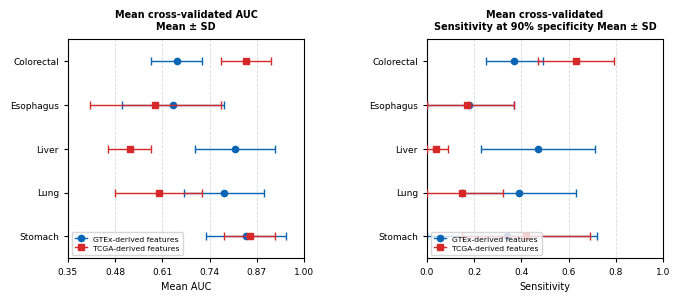

In [10]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(180 / 25.4, 82 / 25.4)
)

plotPairedPerformance(
    bestModelMetricsDF,
    title="Mean cross-validated AUC\nMean ± SD",
    cancerCol="cancerType",
    sourceCol='dataSet',
    meanCol="auc_mean",
    stdCol="auc_std",
    xLabel="Mean AUC",
    xLimits=(0.35, 1.0),
    ax=axes[0]
)

plotPairedPerformance(
    bestModelMetricsDF,
    title="Mean cross-validated\nSensitivity at 90% specificity Mean ± SD",
    cancerCol="cancerType",
    sourceCol='dataSet',
    meanCol="sensitivityAt90Specificity_mean",
    stdCol="sensitivityAt90Specificity_std",
    xLabel="Sensitivity",
    xLimits=(0.0, 1.0),
    ax=axes[1]
)

fig.subplots_adjust(
    left=0.14, right=0.98,
    top=0.85, bottom=0.17,
    wspace=0.52
)